In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import time
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [2]:
train = torchvision.datasets.CIFAR10(root='./', train=True, download=True, transform=transforms.ToTensor())
train_loader = torch.utils.data.DataLoader(train, batch_size=100, shuffle=True)

test = torchvision.datasets.CIFAR10(root='./', train=False, download=True, transform=transforms.ToTensor())
test_loader = torch.utils.data.DataLoader(test, batch_size=100, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


In [3]:
model = torch.nn.Sequential(
    nn.Linear(in_features=32*32*3, out_features=256),
    nn.ReLU(),
    nn.Dropout(0.3), 
    nn.Linear(in_features=256, out_features=128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(in_features=128, out_features=10)
)

loss_func = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.01, weight_decay=1e-5)

In [4]:
for epoch in range(50):    
    for x, y in train_loader:
        input = x.view(-1, 32*32*3)

        # Forward Pass
        output = model(input)

        # Loss + L2 Regularization
        loss = loss_func(output, y) + 1e-4 * sum(torch.pow(p, 2).sum() for p in model.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()

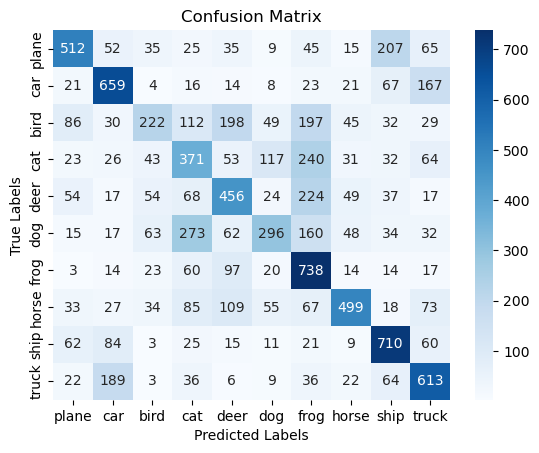

In [5]:
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for x, y in test_loader:
        input = x.view(-1, 32*32*3)

        # Forward Pass
        output = model(input)
        predicted = torch.max(output, 1)[1]
        
        y_true.extend(y)
        y_pred.extend(predicted)

cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [6]:
most_confused = {}
for i, class_name in enumerate(classes):
    row = cm[i, :]
    row[i] = 0  
    most_confused_index = np.argmax(row)
    most_confused[class_name] = classes[most_confused_index]

for class_name, confused_class in most_confused.items():
    print(f"{class_name} : Most confused for : {confused_class}")

plane : Most confused for : ship
car : Most confused for : truck
bird : Most confused for : deer
cat : Most confused for : frog
deer : Most confused for : frog
dog : Most confused for : cat
frog : Most confused for : deer
horse : Most confused for : deer
ship : Most confused for : car
truck : Most confused for : car


In [7]:
confused_pairs = {}
for i in range(len(classes)):
    for j in range(i + 1, len(classes)):
        confused_pairs[(classes[i], classes[j])] = cm[i, j] + cm[j, i]

sorted_confused_pairs = sorted(confused_pairs.items(), key=lambda item: item[1], reverse=True)

print("Two most confused classes overall:")
print(f"{sorted_confused_pairs[0][0]}")

Two most confused classes overall:
('cat', 'dog')


In [8]:
print(sorted_confused_pairs)

[(('cat', 'dog'), 390), (('car', 'truck'), 356), (('deer', 'frog'), 321), (('cat', 'frog'), 300), (('plane', 'ship'), 269), (('bird', 'deer'), 252), (('bird', 'frog'), 220), (('dog', 'frog'), 180), (('deer', 'horse'), 158), (('bird', 'cat'), 155), (('car', 'ship'), 151), (('ship', 'truck'), 124), (('plane', 'bird'), 121), (('cat', 'deer'), 121), (('cat', 'horse'), 116), (('bird', 'dog'), 112), (('dog', 'horse'), 103), (('cat', 'truck'), 100), (('horse', 'truck'), 95), (('plane', 'deer'), 89), (('plane', 'truck'), 87), (('deer', 'dog'), 86), (('frog', 'horse'), 81), (('bird', 'horse'), 79), (('plane', 'car'), 73), (('cat', 'ship'), 57), (('frog', 'truck'), 53), (('deer', 'ship'), 52), (('plane', 'cat'), 48), (('plane', 'frog'), 48), (('plane', 'horse'), 48), (('car', 'horse'), 48), (('dog', 'ship'), 45), (('car', 'cat'), 42), (('dog', 'truck'), 41), (('car', 'frog'), 37), (('bird', 'ship'), 35), (('frog', 'ship'), 35), (('car', 'bird'), 34), (('bird', 'truck'), 32), (('car', 'deer'), 31